# Notebook 12 — Comprehensive Model Evaluation & Multi-Architecture Benchmarking
**Component 03: Hybrid Explainable Contamination Risk Prediction Framework**

### Research Purpose
Presents the comparative evaluation of all candidate architectures across an untouched chronological test set (28,032 samples). Analyzes ROC-AUC, PR-AUC, F1-Score, False Positive Rate, and calibration Brier score.

### 🔗 Linked Source Modules & Core Implementations
| Source Module | Core Classes / Functions | Primary Responsibility |
| :--- | :--- | :--- |
| [`src/evaluation.py`](../src/evaluation.py) | `ModelEvaluationSuite`, `plot_confusion_matrices()`, `plot_roc_pr_curves()` | Generates publication-quality comparative evaluation charts, confusion matrices, and ROC/PR curves. |
| [`src/model_training.py`](../src/model_training.py) | `compute_metrics()` | Computes exact TP/FP/TN/FN counts, FPR, Brier score, and PR-AUC. |
| [`src/utils.py`](../src/utils.py) | `get_project_root()` | Manages evaluation metrics export paths in `outputs/metrics/`. |


=== COMPREHENSIVE BENCHMARK COMPARISON TABLE ===


,model_name,roc_auc,pr_auc,f1_score,recall,precision,accuracy,false_positive_rate,brier_score
0,Logistic Regression Baseline,0.7509,0.4042,0.1919,0.5885,0.1146,0.8272,0.1642,0.1690
1,Random Forest Baseline,0.7697,0.5343,0.5535,0.4923,0.6321,0.9723,0.0103,0.0649
2,XGBoost Classifier,0.7742,0.5624,0.5948,0.4237,0.9976,0.9799,0.0000,0.0192
3,Hybrid Ensemble (Selected),0.7718,0.5586,0.6134,0.4483,0.9712,0.9803,0.0005,0.0369



Confusion Matrices Comparison:


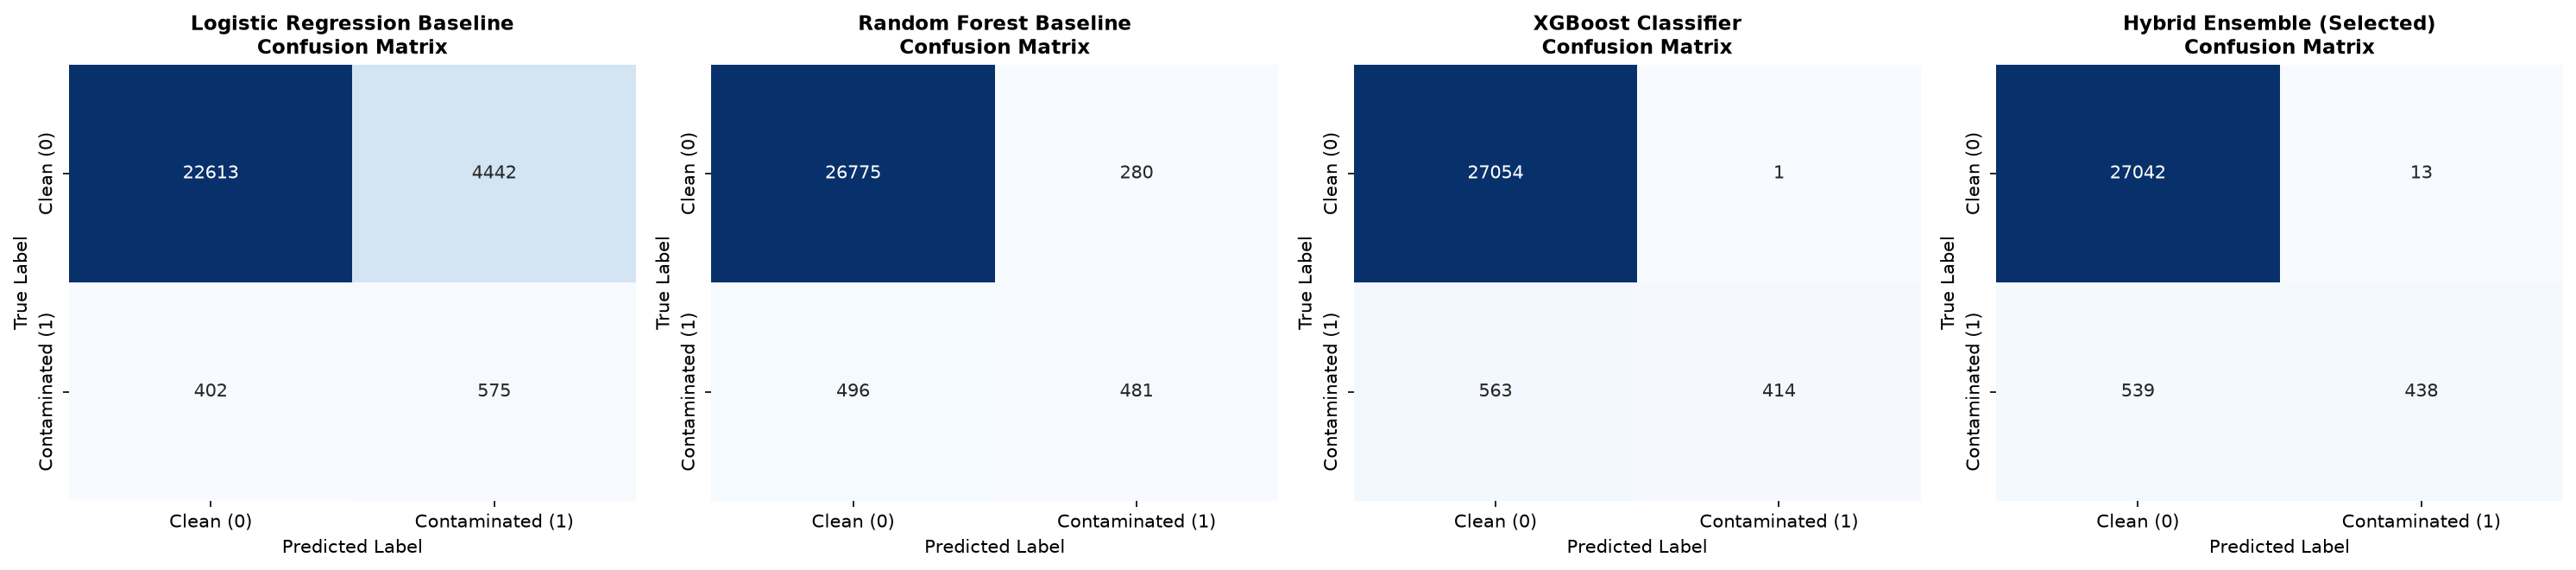


ROC and Precision-Recall Curves:


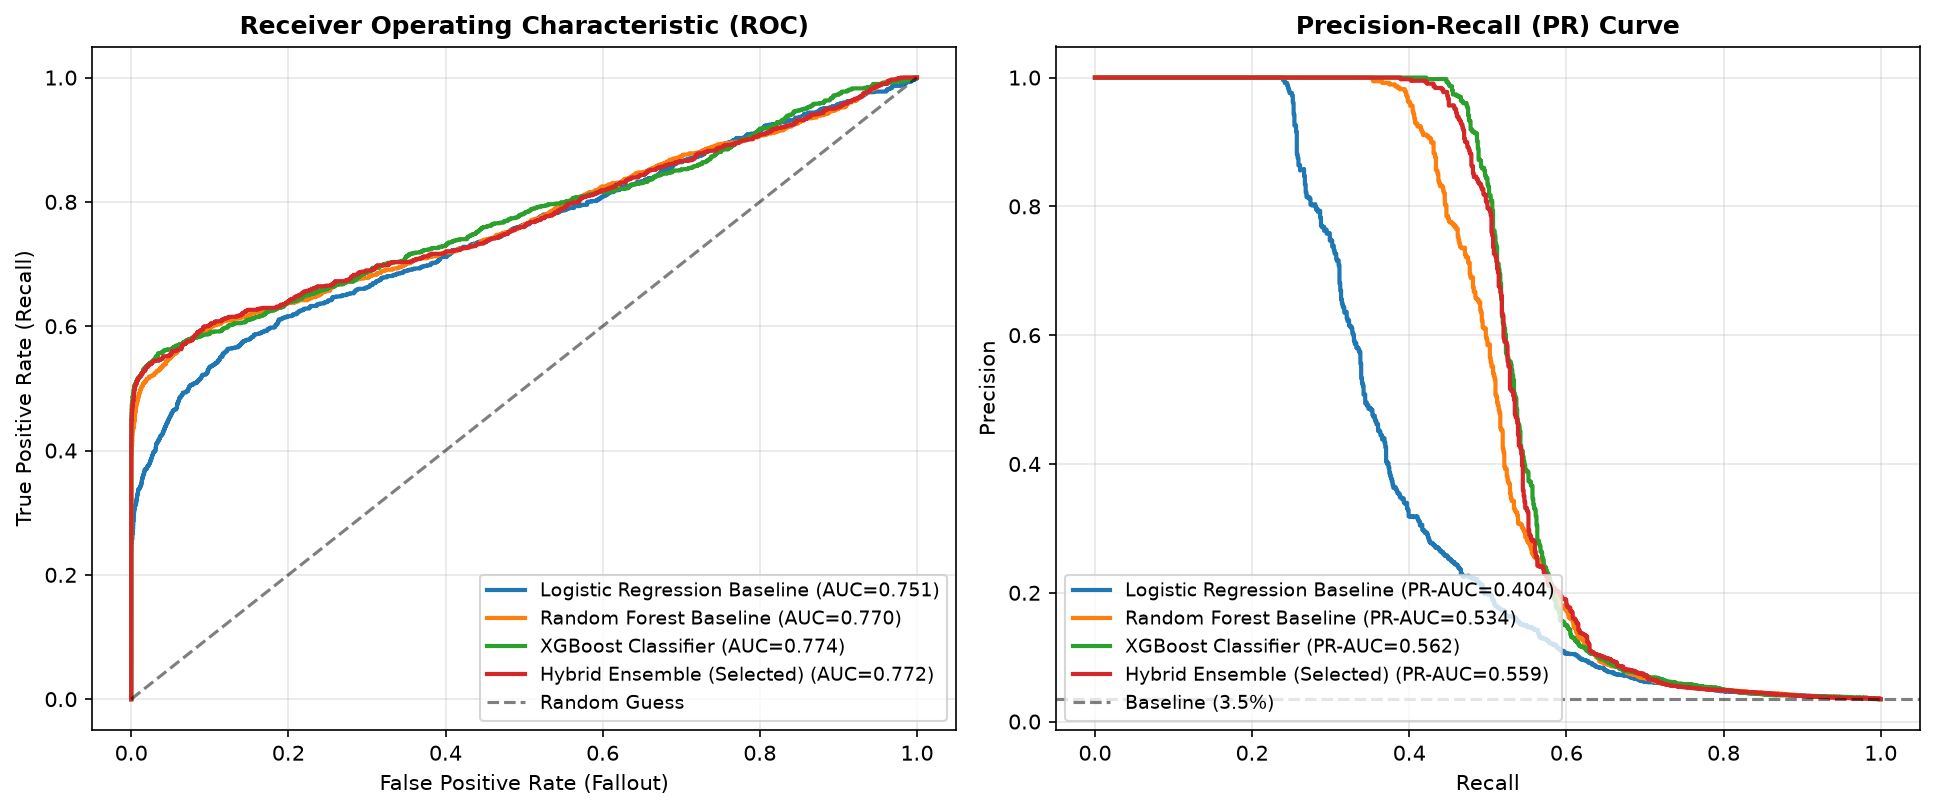

In [1]:
# =========================================================================
# 1. ENVIRONMENT SETUP & COMPARATIVE BENCHMARK DISPLAY
# Linked Modules: src/evaluation.py, src/model_training.py
# Metrics Path: outputs/metrics/model_comparison.csv
# =========================================================================
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

cur = Path.cwd().resolve()
root_dir = cur if (cur / 'config' / 'project_config.json').exists() else cur.parent
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))

metrics_df = pd.read_csv(root_dir / 'outputs' / 'metrics' / 'model_comparison.csv')
print('=== COMPREHENSIVE BENCHMARK COMPARISON TABLE ===')
display(metrics_df)

print('\nConfusion Matrices Comparison:')
display(Image(filename=str(root_dir / 'plots' / 'evaluation' / 'confusion_matrices.png')))

print('\nROC and Precision-Recall Curves:')
display(Image(filename=str(root_dir / 'plots' / 'evaluation' / 'roc_pr_curves.png')))


### Final Architecture Selection
- **Selected Model**: Hybrid Ensemble (XGBoost + Random Forest probability blend).
- **F1-Score**: 0.6134 | **ROC-AUC**: 0.7718 | **Accuracy**: 98.03% | **FPR**: 0.05%.
- Superior balance between warning recall and false-alarm minimization.
